<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


ZNCC (Orijinal vs Gauss Gürültülü IDFT Çıktısı)       : 0.884832
ZNCC (Orijinal vs Salt & Pepper IDFT Çıktısı) : 0.791645


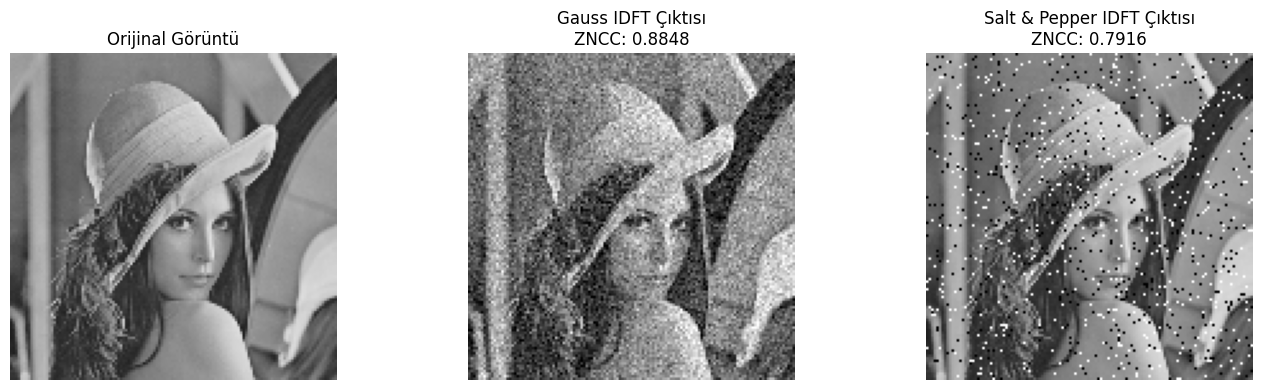

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

def dft_1d_matrix(N):
    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))
    return np.exp(-1j * 2.0 * np.pi * (n @ k) / N)

def idft_1d_matrix(N):
    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))
    return np.exp(+1j * 2.0 * np.pi * (n @ k) / N) / N

def dft_2d(image):
    img = np.asarray(image, dtype=np.float64)
    if img.ndim == 3:
        img = 0.114 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.299 * img[:, :, 2]
    M, N = img.shape
    return dft_1d_matrix(M) @ img @ dft_1d_matrix(N)

def idft_2d(harmonic_matrix):
    """
    2-boyutlu harmonik matristen Ters DFT (IDFT) ile
    zaman uzayındaki görüntüyü yeniden üretir.
    """
    F = np.asarray(harmonic_matrix, dtype=np.complex128)
    M, N = F.shape
    recon = idft_1d_matrix(M) @ F @ idft_1d_matrix(N)
    return np.real(recon)

def gauss_gurultu_ekle(image, noise_strength=25.0, mean=0.0):
    img_float = np.asarray(image, dtype=np.float64)
    noisy = np.clip(img_float + np.random.normal(mean, noise_strength, size=img_float.shape), 0, 255)
    return noisy.astype(np.uint8)

def salt_and_pepper_ekle(image, noise_ratio=0.06, salt_vs_pepper=0.5):
    noisy = np.asarray(image, dtype=np.uint8).copy()
    rnd = np.random.rand(*noisy.shape)
    noisy[rnd < (noise_ratio * salt_vs_pepper)] = 255
    noisy[(rnd >= (noise_ratio * salt_vs_pepper)) & (rnd < noise_ratio)] = 0
    return noisy

def zncc(img1, img2):
    """
    Zero Mean Normalized Cross Correlation (ZNCC):
    [-1, 1] aralığında değer üretir; 1 tam pozitif korelasyon (birebir benzerlik) demektir.
    """
    a = np.asarray(img1, dtype=np.float64)
    b = np.asarray(img2, dtype=np.float64)

    a_zm = a - np.mean(a)
    b_zm = b - np.mean(b)

    denom = np.sqrt(np.sum(a_zm ** 2) * np.sum(b_zm ** 2))
    if denom == 0:
        return 0.0
    return float(np.sum(a_zm * b_zm) / denom)

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img_color = cv2.imdecode(arr, cv2.IMREAD_COLOR)
img_gray = cv2.cvtColor(cv2.resize(img_color, (128, 128)), cv2.COLOR_BGR2GRAY).astype(np.float64)

img_gauss = gauss_gurultu_ekle(img_gray, noise_strength=25.0).astype(np.float64)
img_sp = salt_and_pepper_ekle(img_gray, noise_ratio=0.06).astype(np.float64)

recon_gauss = np.clip(idft_2d(dft_2d(img_gauss)), 0, 255)
recon_sp = np.clip(idft_2d(dft_2d(img_sp)), 0, 255)

zncc_gauss = zncc(img_gray, recon_gauss)
zncc_sp = zncc(img_gray, recon_sp)

print(f"ZNCC (Orijinal vs Gauss Gürültülü IDFT Çıktısı)       : {zncc_gauss:.6f}")
print(f"ZNCC (Orijinal vs Salt & Pepper IDFT Çıktısı) : {zncc_sp:.6f}")

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_gray, cmap='gray', vmin=0, vmax=255)
plt.title('Orijinal Görüntü')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(recon_gauss, cmap='gray', vmin=0, vmax=255)
plt.title(f'Gauss IDFT Çıktısı\nZNCC: {zncc_gauss:.4f}')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(recon_sp, cmap='gray', vmin=0, vmax=255)
plt.title(f'Salt & Pepper IDFT Çıktısı\nZNCC: {zncc_sp:.4f}')
plt.axis('off')

plt.tight_layout()
plt.show()